# 1.Import Depndnice 

In [25]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

# 2.Define a basic CNN model for super-resolution

In [26]:



class BasicSRNet(nn.Module):
    def __init__(self):
        super(BasicSRNet, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=9, stride=1, padding=4)
        self.conv2 = nn.Conv2d(64, 32, kernel_size=5, stride=1, padding=2)
        self.conv3 = nn.Conv2d(32, 3, kernel_size=5, stride=1, padding=2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        x = self.conv3(x)
        return x


# 3.Preprocessing

In [28]:

transform = transforms.Compose([
    transforms.Resize((128, 128)),  # Resize for quick testing
    transforms.ToTensor()
])

# 4.Load dataset

In [29]:

class Urban100Dataset(torch.utils.data.Dataset):
    def __init__(self, image_folder, transform=None):
        self.image_folder = Path(image_folder)
        self.transform = transform
        self.image_paths = list(self.image_folder.glob('*.png'))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path)
        if self.transform:
            image = self.transform(image)
        return image

# Set dataset folder path
image_folder_path = "/Users/alya/Desktop/ML /Albatoal-HW in computer vision /SelfExSR/data/Urban100/badreslution/"
urban_dataset = Urban100Dataset(image_folder=image_folder_path, transform=transform)

# Check if images are loaded
print(f"Found {len(urban_dataset)} images in the folder.")

# Load data
dataloader = DataLoader(urban_dataset, batch_size=4, shuffle=True)

Found 200 images in the folder.


# 5. Initialize model, loss function, and optimizer

In [30]:

model = BasicSRNet().to(device)
criterion = nn.MSELoss()  # Mean Squared Error Loss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


# 6.Train the model on a small subset

In [31]:
num_epochs = 5
for epoch in range(num_epochs):
    running_loss = 0.0
    for i, inputs in enumerate(dataloader):
        inputs = inputs.to(device)
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss:.4f}")


Epoch [1/5], Loss: 1.4629
Epoch [2/5], Loss: 0.3837
Epoch [3/5], Loss: 0.2267
Epoch [4/5], Loss: 0.1460
Epoch [5/5], Loss: 0.1113


# 7.Test the model on a few images

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


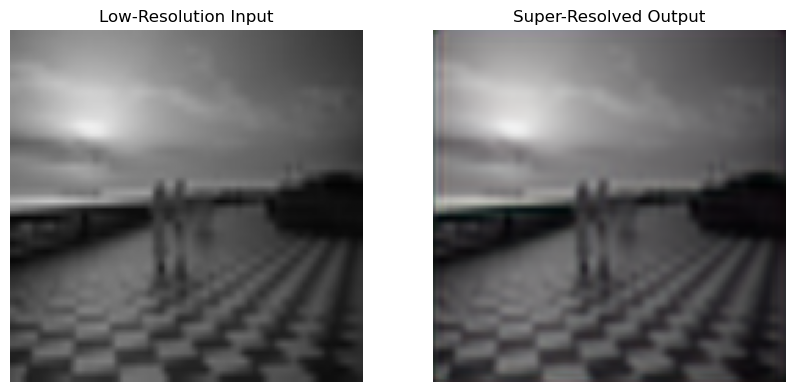

In [101]:

model.eval()  # Set to evaluation mode
with torch.no_grad():
    for i, inputs in enumerate(dataloader):
        inputs = inputs.to(device)
        outputs = model(inputs)
        
        # Visualize the first batch of results
        if i == 0:
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            # Display low-resolution input
            axes[0].imshow(inputs[0].permute(1, 2, 0).cpu())
            axes[0].set_title("Low-Resolution Input")
            axes[0].axis("off")
            
            # Display super-resolved output
            axes[1].imshow(outputs[0].permute(1, 2, 0).cpu())
            axes[1].set_title("Super-Resolved Output")
            axes[1].axis("off")
            plt.show()
            break